In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "../data/one8_sports_final_cleaned.csv"
)

print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (250, 10)


,Product Name,Brand,Category,Price,Available,Total Variants,Total Images,Tags,URL,Price Range
0,Quiet Edge - Silver,One8 Sports Pvt Ltd,Sneakers,5499.0,True,6,4,"Footwear, Lifestyle, Metallic, Quiet Edge, shi...",https://one8.com/products/quiet-edge-urban-sil...,4001-6000
1,Quiet Edge - Orchid,One8 Sports Pvt Ltd,Sneakers,5499.0,True,6,5,"Footwear, Lifestyle, Metallic, Quiet Edge, shi...",https://one8.com/products/quiet-edge-soft-pink...,4001-6000
2,Quiet Edge - Sage,One8 Sports Pvt Ltd,Sneakers,5499.0,True,6,5,"Footwear, Lifestyle, Metallic, Quiet Edge, shi...",https://one8.com/products/quiet-edge-metallic-...,4001-6000
3,Quiet Edge - Cerulean,One8 Sports Pvt Ltd,Sneakers,5499.0,True,6,5,"Footwear, Lifestyle, Metallic, Quiet Edge, shi...",https://one8.com/products/quiet-edge-metallic-...,4001-6000
4,Seam Pavilion - Silver,One8 Sports Pvt Ltd,Sneakers,6999.0,True,6,5,"Footwear, Lifestyle, Seam, seam collection, Se...",https://one8.com/products/seam-pavilion-silver...,6001-8000


# Phase 1 :- Data Overview 

In [2]:
# Dataset Overview

print("DATASET OVERVIEW")
print("-" * 40)

print("Total Records:", df.shape[0])
print("Total Columns:", df.shape[1])

print("\nCOLUMN NAMES:")
print(df.columns.tolist())

print("\nDATA TYPES:")
print(df.dtypes)

print("\nDATASET INFORMATION:")
df.info()

print("\nSTATISTICAL SUMMARY:")
display(df.describe(include="all").T)

DATASET OVERVIEW
----------------------------------------
Total Records: 250
Total Columns: 10

COLUMN NAMES:
['Product Name', 'Brand', 'Category', 'Price', 'Available', 'Total Variants', 'Total Images', 'Tags', 'URL', 'Price Range']

DATA TYPES:
Product Name          str
Brand                 str
Category              str
Price             float64
Available            bool
Total Variants      int64
Total Images        int64
Tags                  str
URL                   str
Price Range           str
dtype: object

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Product Name    250 non-null    str    
 1   Brand           250 non-null    str    
 2   Category        250 non-null    str    
 3   Price           250 non-null    float64
 4   Available       250 non-null    bool   
 5   Total Variants  250 non-null    int64  
 6 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Product Name,250,232,Seam Pavilion - Off White,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Brand,250,1,One8 Sports Pvt Ltd,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,250,11,T-Shirt,61,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,250.0,NaN,NaN,NaN,3658.972,2150.497582,999.0,1999.0,2599.0,4999.0,9999.0
Available,250,1,True,250,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total Variants,250.0,NaN,NaN,NaN,5.608,1.7211,1.0,6.0,6.0,6.0,12.0
Total Images,250.0,NaN,NaN,NaN,5.584,1.08797,4.0,5.0,5.0,6.0,9.0
Tags,250,186,"25Hr, Black, Clothing, Lifestyle, Men, Polo",7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
URL,250,250,https://one8.com/products/quiet-edge-urban-sil...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price Range,250,5,2001-4000,102,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
print("FINAL DATA QUALITY AUDIT")
print("-" * 45)

print("Exact Duplicate Rows:", df.duplicated().sum())

print("Duplicate Product URLs:", df["URL"].duplicated().sum())

print("Missing Values:", df.isnull().sum().sum())

print("Invalid Prices:", (df["Price"] <= 0).sum())

print("Unique Categories:", df["Category"].nunique())

print("Unique Products:", df["Product Name"].nunique())

print("Availability Distribution:")
print(df["Available"].value_counts())

print("\nPrice Statistics:")
print(df["Price"].describe())

FINAL DATA QUALITY AUDIT
---------------------------------------------
Exact Duplicate Rows: 0
Duplicate Product URLs: 0
Missing Values: 0
Invalid Prices: 0
Unique Categories: 11
Unique Products: 232
Availability Distribution:
Available
True    250
Name: count, dtype: int64

Price Statistics:
count     250.000000
mean     3658.972000
std      2150.497582
min       999.000000
25%      1999.000000
50%      2599.000000
75%      4999.000000
max      9999.000000
Name: Price, dtype: float64


### Key Dataset Observations

* **Dataset Size:** 250 product listings across 10 columns.
* **Unique Products:** 232 unique product names.
* **Category Coverage:** 11 product categories.
* **Data Completeness:** No missing values found.
* **Duplicate Check:** No exact duplicate rows or duplicate product URLs.
* **Price Validation:** No invalid or non-positive prices detected.
* **Availability:** All 250 listings are marked as available.

**Data Quality Assessment:** The dataset is structurally complete and contains no detected missing values, duplicate URLs, or invalid prices. It is suitable for further exploratory analysis.

**Important Note:** Since every listing is marked as available, this field has limited analytical value in the current dataset.


# Phase 2:- Category Performance 

In [9]:
category_analysis = (
    df.groupby("Category")
    .agg(
        Product_Count=("Product Name", "count"),
        Unique_Products=("Product Name", "nunique"),
        Average_Price=("Price", "mean"),
        Median_Price=("Price", "median"),
        Minimum_Price=("Price", "min"),
        Maximum_Price=("Price", "max")
    )
    .sort_values("Product_Count", ascending=False)
)

display(category_analysis.round(2))

,Product_Count,Unique_Products,Average_Price,Median_Price,Minimum_Price,Maximum_Price
Category,,,,,,
T-Shirt,61,57,2105.56,1999.0,1599.0,2599.0
Sneakers,52,38,7098.87,6999.0,4999.0,9999.0
Polo,42,42,2496.62,2499.0,1999.0,3499.0
Pants,27,27,4376.78,4299.0,2599.0,5499.0
Caps,26,26,1568.23,1499.0,999.0,1999.0
Leggings,12,12,3524.00,3649.0,2999.0,3799.0
Jacket,11,11,4544.45,4499.0,3999.0,4999.0
Shorts,10,10,3619.00,3699.0,3299.0,3699.0
Short,3,3,1999.00,1999.0,1999.0,1999.0


### Key Business Insights

1. **T-Shirt:** 61 listings — the largest category in the current product catalogue.
2. **Sneakers:** Average listed price of ₹7,098.87 — the highest among the major categories.
3. **Caps:** Average listed price of ₹1,568.23 — the lowest among the categories.
4. **Polo:** 42 listings and 42 unique product names, indicating no repeated product names in this category.

**Business Interpretation:** One8's catalogue has a strong presence in T-Shirts and Sneakers. Sneakers are positioned at a substantially higher average price, while Caps represent a relatively lower-priced category.


# Phase 3:- Pricing Analysis

In [11]:
# Overall Pricing Analysis

price_analysis = df["Price"].describe()

print("OVERALL PRICING ANALYSIS")
print("-" * 40)

print("Total Products:", df["Price"].count())
print("Average Price: ₹", round(df["Price"].mean(), 2))
print("Median Price: ₹", round(df["Price"].median(), 2))
print("Minimum Price: ₹", df["Price"].min())
print("Maximum Price: ₹", df["Price"].max())
print("Standard Deviation: ₹", round(df["Price"].std(), 2))
print("Price Range: ₹", df["Price"].max() - df["Price"].min())

OVERALL PRICING ANALYSIS
----------------------------------------
Total Products: 250
Average Price: ₹ 3658.97
Median Price: ₹ 2599.0
Minimum Price: ₹ 999.0
Maximum Price: ₹ 9999.0
Standard Deviation: ₹ 2150.5
Price Range: ₹ 9000.0


### Key Pricing Insights

1. **Average Listed Price:** ₹3,658.97 across 250 product listings.
2. **Median Listed Price:** ₹2,599, indicating that the middle product listing is priced below the overall average.
3. **Minimum Listed Price:** ₹999 — the lowest-priced product.
4. **Maximum Listed Price:** ₹9,999 — the highest-priced product.
5. **Price Range:** ₹9,000, showing a wide difference between the lowest and highest listed prices.
6. **Standard Deviation:** ₹2,150.50, indicating considerable variation in product prices.

### Business Interpretation

* The average price is higher than the median, suggesting that relatively expensive products may be pulling the average upward.
* One8's catalogue contains products across a broad price spectrum, from ₹999 to ₹9,999.
* The substantial price variation suggests the presence of multiple pricing segments within the product catalogue.

**Conclusion:** One8 has a diverse product pricing structure. Further category-wise analysis will help identify which product categories contribute to the higher and lower price segments.

*Note: These findings describe listed catalogue prices, not actual selling prices or sales performance.*


# Phase 4: Product Assortment Analysis

In [12]:
# Repeated Product Listing Analysis

product_assortment = (
    df.groupby("Product Name")
    .agg(
        Listing_Count=("Product Name", "count"),
        Category=("Category", "first"),
        Price=("Price", "first"),
        Unique_Prices=("Price", "nunique"),
        Unique_URLs=("URL", "nunique")
    )
    .reset_index()
)

repeated_products = (
    product_assortment[
        product_assortment["Listing_Count"] > 1
    ]
    .sort_values("Listing_Count", ascending=False)
)

print("PRODUCT ASSORTMENT ANALYSIS")
print("-" * 45)
print("Total Listings:", len(df))
print("Unique Product Names:", df["Product Name"].nunique())
print("Repeated Product Names:", len(repeated_products))
print("Additional Listings:", len(df) - df["Product Name"].nunique())

display(repeated_products)

PRODUCT ASSORTMENT ANALYSIS
---------------------------------------------
Total Listings: 250
Unique Product Names: 232
Repeated Product Names: 18
Additional Listings: 18


,Product Name,Listing_Count,Category,Price,Unique_Prices,Unique_URLs
7,Arc T-Shirt - Black,2,T-Shirt,2499.0,2,2
9,Arc T-Shirt - White,2,T-Shirt,1999.0,2,2
23,Boom Rush - Classic Black,2,Sneakers,9999.0,1,2
25,Boom Rush - Classic Black and White,2,Sneakers,9999.0,1,2
130,Quiet Edge - White,2,Sneakers,5499.0,1,2
138,Seam Classic - Club Navy & White,2,Sneakers,4999.0,1,2
139,Seam Classic - Field Green & White,2,Sneakers,4999.0,1,2
142,Seam Classic - Legacy Red & White,2,Sneakers,4999.0,1,2
145,Seam Pavilion - Off White,2,Sneakers,6999.0,1,2
155,Seam XVIII OG - Red,2,Sneakers,6999.0,1,2


### Key Business Insights

1. The catalogue contains 250 product listings across 232 unique product names.
2. There are 18 repeated product-name groups, contributing 18 additional listings.
3. Every repeated-name group has two distinct URLs, indicating separate catalogue listings.
4. Some repeated product names have different listed prices, highlighting potential price variation.

**Business Interpretation:** Product names alone are not sufficient to identify unique catalogue listings. URL-level identification is more reliable for this dataset.

**Conclusion:** Repeated product names should not automatically be treated as duplicate records. Further analysis should consider product URLs, prices and product attributes.

# Phase 5: Business Insights & Recommendations

In [13]:
# Price Segment Distribution

price_segment = (
    df.groupby("Price Range")
    .agg(
        Product_Count=("Product Name", "count"),
        Average_Price=("Price", "mean")
    )
    .sort_values("Product_Count", ascending=False)
)

price_segment["Percentage"] = (
    price_segment["Product_Count"] / len(df) * 100
)

display(price_segment.round(2))

,Product_Count,Average_Price,Percentage
Price Range,,,
2001-4000,102,2870.57,40.8
0-2000,69,1781.61,27.6
4001-6000,44,4985.36,17.6
6001-8000,22,7044.45,8.8
8001-10000,13,9590.77,5.2


### Key Business Insights

1. The ₹2,001–₹4,000 segment dominates the catalogue, accounting for 102 listings (40.8%).
2. The ₹0–₹2,000 segment contains 69 listings (27.6%).
3. Together, the ₹0–₹4,000 segments represent 68.4% of total catalogue listings.
4. Premium products priced between ₹8,001 and ₹10,000 represent only 5.2% of listings.

**Business Interpretation:** One8's current product catalogue has a stronger concentration in lower-to-mid-priced products, while higher-priced products represent a relatively smaller portion.

**Conclusion:** The catalogue appears positioned primarily around the ₹0–₹4,000 price range. This describes listed product-price distribution, not customer demand or sales performance.


In [15]:
# Category-Wise Price Segments 
category_pricing = (
    df.groupby("Category")
    .agg(
        Product_Count=("Product Name", "count"),
        Average_Price=("Price", "mean"),
        Median_Price=("Price", "median"),
        Minimum_Price=("Price", "min"),
        Maximum_Price=("Price", "max")
    )
    .sort_values("Average_Price", ascending=False)
)

display(category_pricing.round(2))

,Product_Count,Average_Price,Median_Price,Minimum_Price,Maximum_Price
Category,,,,,
Sneakers,52,7098.87,6999.0,4999.0,9999.0
Jacket,11,4544.45,4499.0,3999.0,4999.0
Sweatshirt,3,4499.00,4499.0,4499.0,4499.0
Pants,27,4376.78,4299.0,2599.0,5499.0
Shorts,10,3619.00,3699.0,3299.0,3699.0
Leggings,12,3524.00,3649.0,2999.0,3799.0
Polo,42,2496.62,2499.0,1999.0,3499.0
T-Shirt,61,2105.56,1999.0,1599.0,2599.0
Short,3,1999.00,1999.0,1999.0,1999.0


### Business Insights – Category-wise Pricing

1. **Sneakers:** Highest average listed price at ₹7,098.87, indicating premium catalogue positioning.
2. **Jackets:** Average listed price of ₹4,544.45, making them the second-highest-priced category.
3. **Pants:** Average listed price of ₹4,376.78.
4. **T-Shirts:** Largest category with 61 listings, but the average listed price is ₹2,105.56.
5. **Caps:** Lowest average listed price at ₹1,568.23.

**Business Interpretation:** One8's catalogue includes distinct price positions across product categories. Sneakers and Jackets occupy the higher-priced segments, whereas T-Shirts and Caps are positioned at relatively lower price points.

**Conclusion:** Category-wise pricing analysis highlights differences in catalogue positioning and product assortment. Categories with very few listings should be interpreted cautiously.

**Note:** These findings represent listed catalogue prices, not actual sales or customer demand.

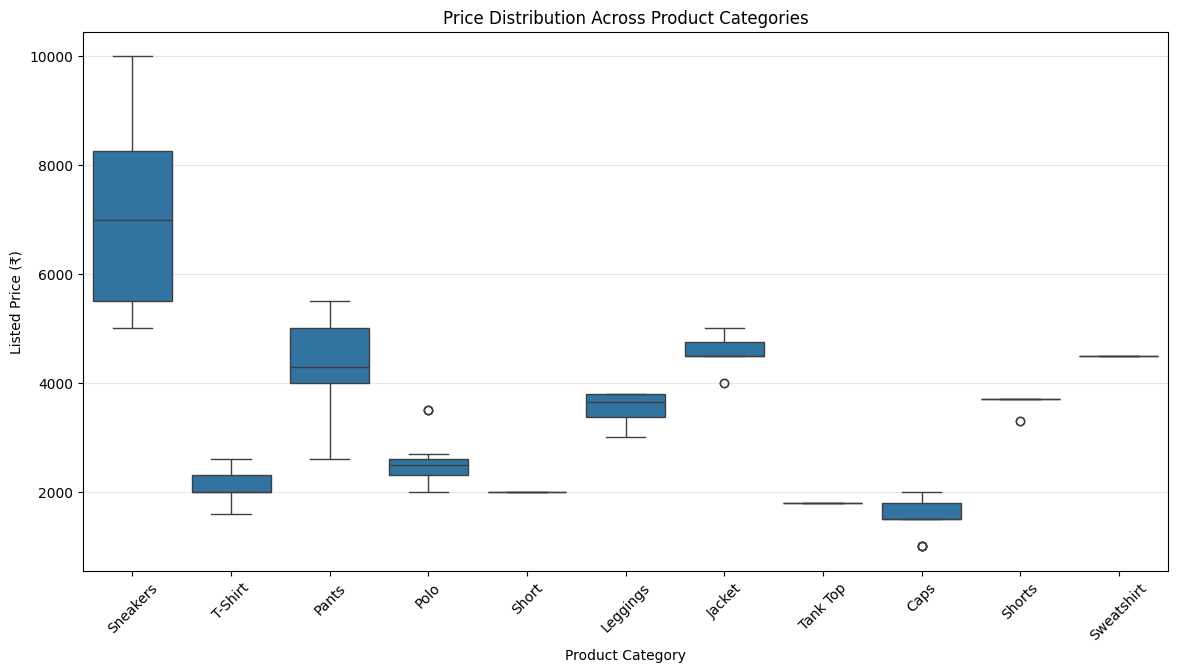

In [16]:
# Category-wise Price Distribution

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="Category",
    y="Price"
)

plt.title("Price Distribution Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Listed Price (₹)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.show()

### Business Insights – Category-wise Price Distribution

1. **Sneakers:** Show the widest price distribution, indicating considerable variation in listed prices.
2. **Pants:** Also demonstrate substantial price variation compared with most other categories.
3. **T-Shirts:** Have a relatively concentrated price distribution, suggesting more consistent catalogue pricing.
4. **Polo:** Contains a higher-priced outlier compared with its other listings.
5. **Jackets and Caps:** Show potential price outliers that may require further investigation.

**Business Interpretation:** One8's catalogue demonstrates different pricing patterns across categories. Sneakers and Pants have wider price distributions, whereas T-Shirts have relatively consistent listed prices.

**Conclusion:** Category-wise price distribution helps identify pricing variation and unusual listings. These observations can support further product-level pricing analysis.

**Note:** Outliers are not necessarily data errors. Categories with small sample sizes should be interpreted cautiously.

In [17]:
# Brand-wise Catalogue Analysis

brand_analysis = (
    df.groupby("Brand")
    .agg(
        Product_Count=("Product Name", "count"),
        Average_Price=("Price", "mean"),
        Median_Price=("Price", "median"),
        Minimum_Price=("Price", "min"),
        Maximum_Price=("Price", "max")
    )
    .sort_values("Product_Count", ascending=False)
)

brand_analysis = brand_analysis.round(2)

display(brand_analysis)

,Product_Count,Average_Price,Median_Price,Minimum_Price,Maximum_Price
Brand,,,,,
One8 Sports Pvt Ltd,250,3658.97,2599.0,999.0,9999.0


## Business Insights – Brand-wise Catalogue Analysis

1. The dataset contains 250 product listings, all assigned to One8 Sports Pvt Ltd.
2. Only one unique brand is represented in the dataset.
3. The average listed price is ₹3,658.97, while the median is ₹2,599.
4. Listed prices range from ₹999 to ₹9,999.

**Business Interpretation:** The dataset represents a single-brand catalogue. Therefore, brand-level price comparisons and competitive positioning cannot be evaluated.

**Conclusion:** Brand-wise analysis has limited analytical value for this dataset. Further analysis should focus on product categories, pricing segments and product attributes.

In [18]:
# Product Availability Analysis

availability_analysis = (
    df["Available"]
    .value_counts(dropna=False)
    .reset_index()
)

availability_analysis.columns = ["Availability_Status", "Product_Count"]

availability_analysis["Percentage"] = (
    availability_analysis["Product_Count"] / len(df) * 100
)

display(availability_analysis.round(2))

print("Unique Availability Values:", df["Available"].nunique())
print("Missing Availability Values:", df["Available"].isna().sum())

,Availability_Status,Product_Count,Percentage
0,True,250,100.0


Unique Availability Values: 1
Missing Availability Values: 0


## Business Insights – Product Availability Analysis

1. The dataset contains 250 product listings.
2. All 250 listings (100%) are marked as Available = True.
3. No products are marked as unavailable.
4. The Available column contains only one unique value.
5. There are no missing availability values.

**Business Interpretation:** The availability field provides no differentiation across the current product catalogue.

**Conclusion:** Product availability analysis is limited because the dataset contains no variation in availability status. The scraping logic should be reviewed to verify whether this field reflects actual website availability or a default value.

**Note:** This dataset alone does not establish the real-time stock status of products.

In [19]:
# Inspect Product Tags Structure

print("Tags Data Type:", df["Tags"].dtype)

print("\nFirst 10 Raw Tag Values:")
for i, tag in enumerate(df["Tags"].head(10), start=1):
    print(f"{i}. {tag}")

print("\nTotal Unique Tag Combinations:", df["Tags"].nunique())

Tags Data Type: str

First 10 Raw Tag Values:
1. Footwear, Lifestyle, Metallic, Quiet Edge, shine edit, Sneakers, Stories from cricket, Women
2. Footwear, Lifestyle, Metallic, Quiet Edge, shine edit, Sneakers, Stories from cricket, Women
3. Footwear, Lifestyle, Metallic, Quiet Edge, shine edit, Sneakers, Stories from cricket, Women
4. Footwear, Lifestyle, Metallic, Quiet Edge, shine edit, Sneakers, Stories from cricket, Women
5. Footwear, Lifestyle, Seam, seam collection, Seam Pavilion, shine edit, Sneakers, Women
6. Footwear, Lifestyle, Seam, seam collection, Seam Pavilion, shine edit, Women
7. Footwear, Lifestyle, Seam, seam collection, Seam Pavilion, shine edit, Sneakers, Women
8. Footwear, Lifestyle, Seam, seam collection, Seam Pavilion, Sneakers, Women
9. Footwear, Lifestyle, Pink, Seam, seam collection, Seam XVIII X, Sneakers, Stories from cricket, Women
10. Black, Boom Rush, Footwear, High Performance, Men, Red, Running, Training, Virat's Training Essentials

Total Unique Tag Co

In [20]:
# Extract Individual Product Tags

tag_analysis = (
    df["Tags"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
)

tag_frequency = (
    tag_analysis
    .value_counts()
    .reset_index()
)

tag_frequency.columns = ["Tag", "Frequency"]

tag_frequency["Percentage"] = (
    tag_frequency["Frequency"] / len(df) * 100
)

display(tag_frequency.head(20).round(2))

print("Total Unique Individual Tags:", tag_analysis.nunique())
print("Total Tag Occurrences:", len(tag_analysis))

,Tag,Frequency,Percentage
0,Lifestyle,199,79.6
1,Men,182,72.8
2,Clothing,172,68.8
3,25Hr,92,36.8
4,Women,91,36.4
5,Black,72,28.8
6,Stories from cricket,64,25.6
7,T-shirts,60,24.0
8,Footwear,52,20.8
9,seam collection,46,18.4


Total Unique Individual Tags: 67
Total Tag Occurrences: 1700


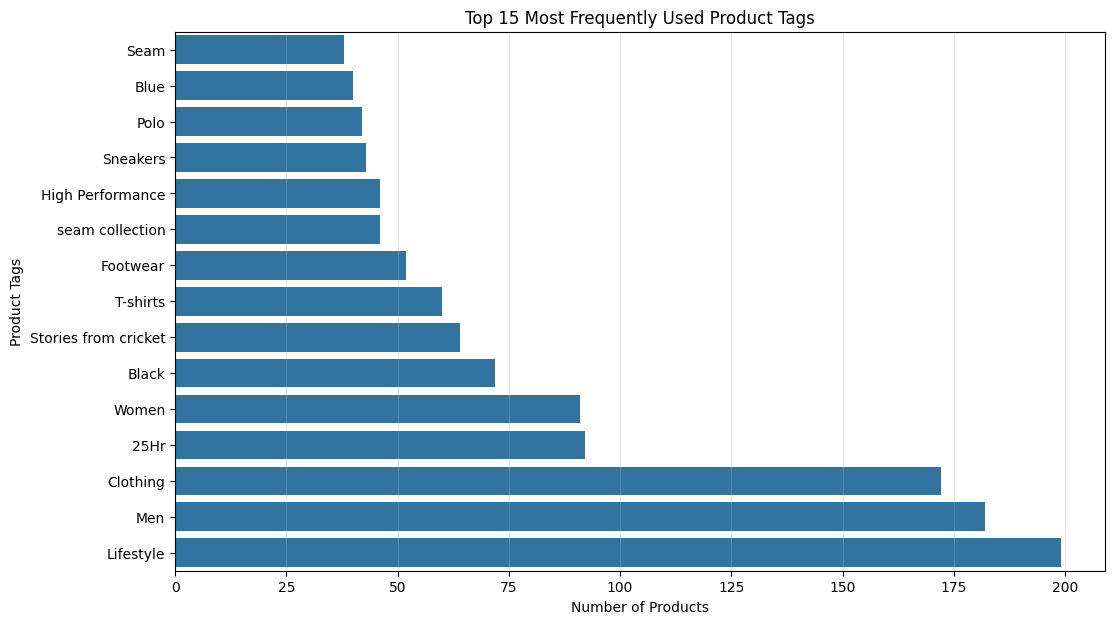

In [21]:
# Top 15 Most Frequently Used Product Tags

top_tags = tag_frequency.head(15).sort_values(
    "Frequency",
    ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_tags,
    x="Frequency",
    y="Tag"
)

plt.title("Top 15 Most Frequently Used Product Tags")
plt.xlabel("Number of Products")
plt.ylabel("Product Tags")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [22]:
# Tag Classification – Business Grouping

tag_groups = {
    # Audience
    "Men": "Audience",
    "Women": "Audience",

    # Product Type
    "Clothing": "Product Type",
    "Footwear": "Product Type",
    "Sneakers": "Product Type",
    "T-shirts": "Product Type",
    "Polo": "Product Type",
    "Pants": "Product Type",
    "Caps": "Product Type",
    "Accessories": "Product Type",

    # Colour
    "Black": "Colour",
    "Blue": "Colour",
    "White": "Colour",
    "Pink": "Colour",
    "Red": "Colour",

    # Collection / Campaign
    "Seam": "Collection/Campaign",
    "seam collection": "Collection/Campaign",
    "Seam Pavilion": "Collection/Campaign",
    "Stories from cricket": "Collection/Campaign",
    "Boom Rush": "Collection/Campaign",
    "Virat's Training Essentials": "Collection/Campaign",

    # Usage / Positioning
    "Lifestyle": "Usage/Positioning",
    "High Performance": "Usage/Positioning",
    "Running": "Usage/Positioning",
    "Training": "Usage/Positioning",
    "Yoga": "Usage/Positioning",
    "25Hr": "Usage/Positioning"
}

# Create a structured tag dataset
tag_classification = pd.DataFrame({
    "Tag": tag_analysis.unique()
})

tag_classification["Business_Group"] = (
    tag_classification["Tag"].map(tag_groups).fillna("Unclassified")
)

display(
    tag_classification.sort_values(
        "Business_Group"
    ).reset_index(drop=True)
)

print("Total Unique Tags:", len(tag_classification))
print(
    "Unclassified Tags:",
    (tag_classification["Business_Group"] == "Unclassified").sum()
)

,Tag,Business_Group
0,Men,Audience
1,Women,Audience
2,seam collection,Collection/Campaign
3,Boom Rush,Collection/Campaign
4,Seam Pavilion,Collection/Campaign
...,...,...
62,Yoga,Usage/Positioning
63,25Hr,Usage/Positioning
64,Training,Usage/Positioning
65,Lifestyle,Usage/Positioning


Total Unique Tags: 67
Unclassified Tags: 40


In [23]:
# Unclassified Tags – Frequency Audit

unclassified_tags = (
    tag_classification[
        tag_classification["Business_Group"] == "Unclassified"
    ]["Tag"]
)

unclassified_analysis = (
    tag_frequency[
        tag_frequency["Tag"].isin(unclassified_tags)
    ]
    .sort_values("Frequency", ascending=False)
    .reset_index(drop=True)
)

display(unclassified_analysis)

print("Total Unclassified Tags:", len(unclassified_analysis))
print(
    "Products Covered by Unclassified Tags:",
    unclassified_analysis["Frequency"].sum()
)

,Tag,Frequency,Percentage
0,Brown,17,6.8
1,Bestsellers-Tshirts,16,6.4
2,Green,15,6.0
3,Bestsellers-Polos,14,5.6
4,Shorts,13,5.2
5,Leggings,12,4.8
6,Jackets,11,4.4
7,nm-test,10,4.0
8,Quiet Edge,9,3.6
9,Bestsellers-Pants-Men,9,3.6


Total Unclassified Tags: 40
Products Covered by Unclassified Tags: 244


In [28]:
# Complete Unclassified Tag Audit

display(
    unclassified_analysis
    .sort_values("Frequency", ascending=False)
    .reset_index(drop=True)
)

print("Total Unclassified Tags:", len(unclassified_analysis))
print("Total Tag Occurrences:", unclassified_analysis["Frequency"].sum())

,Tag,Frequency,Percentage
0,Brown,17,6.8
1,Bestsellers-Tshirts,16,6.4
2,Green,15,6.0
3,Bestsellers-Polos,14,5.6
4,Shorts,13,5.2
5,Leggings,12,4.8
6,Jackets,11,4.4
7,nm-test,10,4.0
8,Quiet Edge,9,3.6
9,Bestsellers-Pants-Men,9,3.6


Total Unclassified Tags: 40
Total Tag Occurrences: 244


In [29]:
# Inspect Existing Business Groups

print("Existing Business Groups:")
print(tag_classification["Business_Group"].value_counts())

print("\nCurrent Classification Sample:")
display(tag_classification.head(15))

Existing Business Groups:
Business_Group
Unclassified           40
Product Type            8
Usage/Positioning       6
Collection/Campaign     6
Colour                  5
Audience                2
Name: count, dtype: int64

Current Classification Sample:


,Tag,Business_Group
0,Footwear,Product Type
1,Lifestyle,Usage/Positioning
2,Metallic,Unclassified
3,Quiet Edge,Unclassified
4,shine edit,Unclassified
5,Sneakers,Product Type
6,Stories from cricket,Collection/Campaign
7,Women,Audience
8,Seam,Collection/Campaign
9,seam collection,Collection/Campaign


In [30]:
# Classify Remaining Unclassified Tags

tag_mapping = {

    # Colour
    "Brown": "Colour",
    "Green": "Colour",
    "Beige": "Colour",
    "Olive": "Colour",
    "Peacock": "Colour",
    "Off White": "Colour",
    "Grey": "Colour",
    "Purple": "Colour",
    "Metallic": "Colour",
    "Gray": "Colour",
    "Maroon": "Colour",
    "Orange": "Colour",
    "Mint Green": "Colour",
    "Dark Navy": "Colour",

    # Product Type
    "Shorts": "Product Type",
    "Leggings": "Product Type",
    "Jackets": "Product Type",
    "Tank Tops": "Product Type",
    "Sweatshirts": "Product Type",

    # Collection/Campaign
    "Bestsellers-Tshirts": "Collection/Campaign",
    "Bestsellers-Polos": "Collection/Campaign",
    "Bestsellers-Pants-Men": "Collection/Campaign",
    "Quiet Edge": "Collection/Campaign",
    "shine edit": "Collection/Campaign",
    "Seam XVIII X": "Collection/Campaign",
    "Seam XVIII Signature": "Collection/Campaign",
    "Seam XVIII OG": "Collection/Campaign",
    "Seam XVIII": "Collection/Campaign",
    "Cover Drive": "Collection/Campaign",

    # Usage/Positioning
    "gym": "Usage/Positioning",
    "Active Lifestyle": "Usage/Positioning",
    "Sports": "Usage/Positioning",
    "Cricket": "Usage/Positioning",

    # Audience
    "Kids": "Audience",

    # Promotion/Status
    "Selling Fast": "Promotion/Status",
    "early-access": "Promotion/Status",
    "Limited edition drop": "Promotion/Status",

    # Needs Review
    "nm-test": "Needs Review",
    "hold": "Needs Review",
    "cricket cap": "Needs Review"
}

# Update only previously unclassified tags
mask = tag_classification["Business_Group"] == "Unclassified"

tag_classification.loc[mask, "Business_Group"] = (
    tag_classification.loc[mask, "Tag"]
    .map(tag_mapping)
    .fillna("Needs Review")
)

display(tag_classification)

,Tag,Business_Group
0,Footwear,Product Type
1,Lifestyle,Usage/Positioning
2,Metallic,Colour
3,Quiet Edge,Collection/Campaign
4,shine edit,Collection/Campaign
...,...,...
62,Maroon,Colour
63,Sweatshirts,Product Type
64,Orange,Colour
65,Mint Green,Colour


In [31]:
# Final Business Group Classification Audit

classification_summary = (
    tag_classification["Business_Group"]
    .value_counts()
    .reset_index()
)

classification_summary.columns = ["Business_Group", "Tag_Count"]

classification_summary["Percentage"] = (
    classification_summary["Tag_Count"] /
    len(tag_classification) * 100
)

display(classification_summary.round(2))

print("Total Tags:", len(tag_classification))
print(
    "Tags Needing Review:",
    (tag_classification["Business_Group"] == "Needs Review").sum()
)

,Business_Group,Tag_Count,Percentage
0,Colour,18,26.87
1,Collection/Campaign,16,23.88
2,Product Type,13,19.40
3,Usage/Positioning,10,14.93
4,Needs Review,4,5.97
5,Audience,3,4.48
6,Promotion/Status,3,4.48


Total Tags: 67
Tags Needing Review: 4


In [32]:
display(
    tag_classification[
        tag_classification["Business_Group"] == "Needs Review"
    ]
)

,Tag,Business_Group
50,nm-test,Needs Review
53,hold,Needs Review
56,Peacoat,Needs Review
59,cricket cap,Needs Review


In [33]:
review_tags = ["nm-test", "hold", "Peacoat", "cricket cap"]

display(
    df[
        df["Tags"].str.contains(
            "|".join(review_tags),
            case=False,
            na=False
        )
    ][["Product Name", "Category", "Tags"]]
)

,Product Name,Category,Tags
54,Seam XVIII OG - White,Sneakers,"Footwear, Lifestyle, Men, nm-test, Seam, seam ..."
69,Seam XVIII OG - White Brown,Sneakers,"Footwear, Lifestyle, Men, nm-test, Seam, seam ..."
70,Seam XVIII OG - Red,Sneakers,"Brown, Footwear, Lifestyle, Men, nm-test, Red,..."
71,Seam XVIII OG - White,Sneakers,"Footwear, Lifestyle, nm-test, Seam, seam colle..."
72,Seam XVIII OG - Red,Sneakers,"Brown, Footwear, Lifestyle, nm-test, Red, Seam..."
73,Seam XVIII Signature - White,Sneakers,"Footwear, Lifestyle, nm-test, Seam, seam colle..."
74,Seam XVIII Signature - White,Sneakers,"Footwear, Lifestyle, Men, nm-test, Seam, seam ..."
75,Seam XVIII Signature - Red,Sneakers,"Brown, Footwear, Lifestyle, Men, nm-test, Red,..."
76,Seam XVIII Signature - Red,Sneakers,"Brown, Footwear, hold, Lifestyle, nm-test, Red..."
77,Seam XVIII OG - White Brown,Sneakers,"Footwear, Lifestyle, nm-test, Seam, seam colle..."


In [34]:
tag_mapping.update({
    "Peacoat": "Colour",
    "cricket cap": "Product Type",
    "hold": "Promotion/Status"
})

In [35]:
mask = tag_classification["Business_Group"] == "Needs Review"

tag_classification.loc[mask, "Business_Group"] = (
    tag_classification.loc[mask, "Tag"]
    .map(tag_mapping)
    .fillna("Needs Review")
)

display(
    tag_classification[
        tag_classification["Business_Group"] == "Needs Review"
    ]
)

,Tag,Business_Group
50,nm-test,Needs Review


In [36]:
classification_summary = (
    tag_classification["Business_Group"]
    .value_counts()
    .reset_index()
)

classification_summary.columns = ["Business_Group", "Tag_Count"]

classification_summary["Percentage"] = (
    classification_summary["Tag_Count"]
    / len(tag_classification) * 100
)

display(classification_summary.round(2))

print("Total Tags:", len(tag_classification))
print(
    "Tags Needing Review:",
    (tag_classification["Business_Group"] == "Needs Review").sum()
)

,Business_Group,Tag_Count,Percentage
0,Colour,19,28.36
1,Collection/Campaign,16,23.88
2,Product Type,14,20.90
3,Usage/Positioning,10,14.93
4,Promotion/Status,4,5.97
5,Audience,3,4.48
6,Needs Review,1,1.49


Total Tags: 67
Tags Needing Review: 1


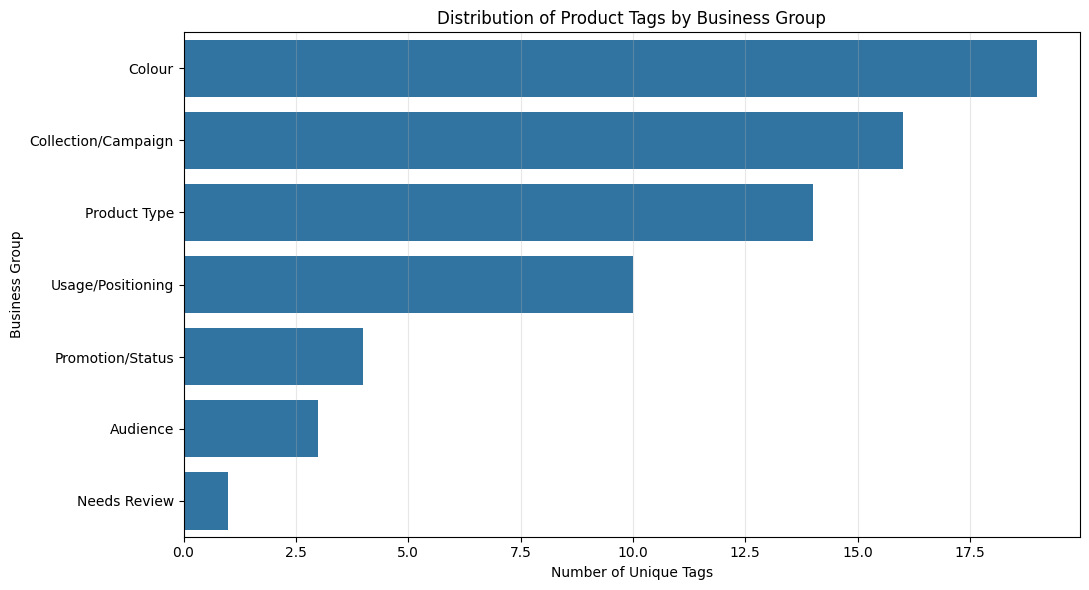

In [37]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=classification_summary,
    x="Tag_Count",
    y="Business_Group"
)

plt.title("Distribution of Product Tags by Business Group")
plt.xlabel("Number of Unique Tags")
plt.ylabel("Business Group")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

In [38]:
# Convert product tags into individual rows
product_tags = (
    df[["Product Name", "Category", "Tags"]]
    .assign(Tag=df["Tags"].fillna("").str.split(","))
    .explode("Tag")
)

# Clean tag values
product_tags["Tag"] = product_tags["Tag"].str.strip()

# Map tags to business groups
product_tags = product_tags.merge(
    tag_classification,
    on="Tag",
    how="left"
)

# Analyse product coverage by business group
group_analysis = (
    product_tags
    .groupby("Business_Group")
    .agg(
        Unique_Tags=("Tag", "nunique"),
        Product_Count=("Product Name", "nunique"),
        Total_Tag_Assignments=("Product Name", "count")
    )
    .reset_index()
    .sort_values("Product_Count", ascending=False)
)

display(group_analysis)

,Business_Group,Unique_Tags,Product_Count,Total_Tag_Assignments
0,Audience,3,232,276
6,Usage/Positioning,10,232,406
4,Product Type,14,232,491
2,Colour,19,228,258
1,Collection/Campaign,16,104,251
5,Promotion/Status,4,6,8
3,Needs Review,1,5,10


In [39]:
product_tag_coverage = (
    product_tags
    .groupby("Product Name")
    .agg(
        Total_Tags=("Tag", "count"),
        Unique_Business_Groups=("Business_Group", "nunique")
    )
    .reset_index()
)

display(
    product_tag_coverage
    .sort_values("Total_Tags", ascending=False)
    .head(15)
)

print("Average Tags per Product:",
      round(product_tag_coverage["Total_Tags"].mean(), 2))

print("Average Business Groups per Product:",
      round(product_tag_coverage["Unique_Business_Groups"].mean(), 2))

,Product Name,Total_Tags,Unique_Business_Groups
163,Seam XVIII Signature - Red,23,7
155,Seam XVIII OG - Red,22,6
156,Seam XVIII OG - White,20,6
157,Seam XVIII OG - White Brown,20,6
165,Seam XVIII Signature - White,20,6
166,Seam XVIII X - Black,18,5
170,Seam XVIII X - White,18,5
138,Seam Classic - Club Navy & White,17,5
139,Seam Classic - Field Green & White,17,5
142,Seam Classic - Legacy Red & White,17,5


Average Tags per Product: 7.33
Average Business Groups per Product: 4.48


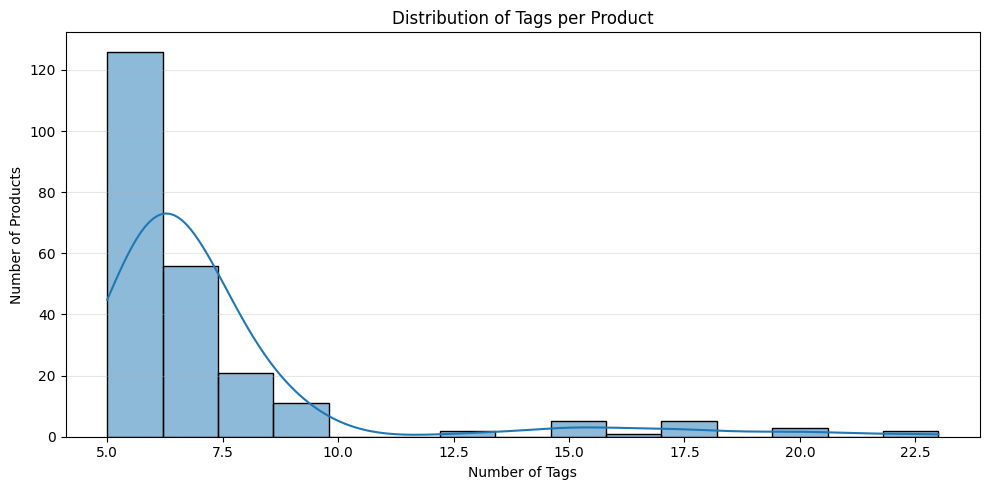

In [40]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=product_tag_coverage,
    x="Total_Tags",
    bins=15,
    kde=True
)

plt.title("Distribution of Tags per Product")
plt.xlabel("Number of Tags")
plt.ylabel("Number of Products")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
tag_distribution = pd.cut(
    product_tag_coverage["Total_Tags"],
    bins=[0, 7, 10, float("inf")],
    labels=["Low (1-7)", "Medium (8-10)", "High (11+)"]
)

tag_summary = (
    tag_distribution
    .value_counts()
    .reset_index()
)

tag_summary.columns = ["Tag_Category", "Product_Count"]

tag_summary["Percentage"] = (
    tag_summary["Product_Count"]
    / len(product_tag_coverage) * 100
).round(2)

display(tag_summary)

,Tag_Category,Product_Count,Percentage
0,Low (1-7),182,78.45
1,Medium (8-10),32,13.79
2,High (11+),18,7.76


In [42]:
category_tag_analysis = (
    product_tags
    .groupby(["Category", "Product Name"])
    .agg(Total_Tags=("Tag", "count"))
    .reset_index()
    .groupby("Category")
    .agg(
        Product_Count=("Product Name", "nunique"),
        Average_Tags=("Total_Tags", "mean"),
        Maximum_Tags=("Total_Tags", "max")
    )
    .reset_index()
    .sort_values("Average_Tags", ascending=False)
)

category_tag_analysis[
    ["Average_Tags", "Maximum_Tags"]
] = category_tag_analysis[
    ["Average_Tags", "Maximum_Tags"]
].round(2)

display(category_tag_analysis)

,Category,Product_Count,Average_Tags,Maximum_Tags
7,Sneakers,38,11.79,23
6,Shorts,10,7.10,9
8,Sweatshirt,3,7.00,7
9,T-Shirt,57,6.84,16
3,Pants,27,6.37,9
4,Polo,42,6.33,8
0,Caps,26,6.27,7
1,Jacket,11,6.09,7
2,Leggings,12,6.00,7
5,Short,3,5.00,5


In [43]:
category_audit = (
    df["Category"]
    .value_counts()
    .reset_index()
)

category_audit.columns = ["Category", "Product_Count"]

display(category_audit)
print("Total Unique Categories:", df["Category"].nunique())

,Category,Product_Count
0,T-Shirt,61
1,Sneakers,52
2,Polo,42
3,Pants,27
4,Caps,26
5,Leggings,12
6,Jacket,11
7,Shorts,10
8,Short,3
9,Tank Top,3


Total Unique Categories: 11


In [44]:
category_mapping = {
    "Short": "Shorts",
    "Jacket": "Jackets"
}

df["Category"] = df["Category"].replace(category_mapping)

category_audit = (
    df["Category"]
    .value_counts()
    .reset_index()
)

category_audit.columns = ["Category", "Product_Count"]

display(category_audit)

print("Total Unique Categories:", df["Category"].nunique())

,Category,Product_Count
0,T-Shirt,61
1,Sneakers,52
2,Polo,42
3,Pants,27
4,Caps,26
5,Shorts,13
6,Leggings,12
7,Jackets,11
8,Tank Top,3
9,Sweatshirt,3


Total Unique Categories: 10


In [45]:
category_price_analysis = (
    df.groupby("Category")["Price"]
    .agg(
        Product_Count="count",
        Average_Price="mean",
        Median_Price="median",
        Minimum_Price="min",
        Maximum_Price="max"
    )
    .reset_index()
    .sort_values("Average_Price", ascending=False)
)

display(category_price_analysis.round(2))

,Category,Product_Count,Average_Price,Median_Price,Minimum_Price,Maximum_Price
6,Sneakers,52,7098.87,6999.0,4999.0,9999.0
1,Jackets,11,4544.45,4499.0,3999.0,4999.0
7,Sweatshirt,3,4499.00,4499.0,4499.0,4499.0
3,Pants,27,4376.78,4299.0,2599.0,5499.0
2,Leggings,12,3524.00,3649.0,2999.0,3799.0
5,Shorts,13,3245.15,3699.0,1999.0,3699.0
4,Polo,42,2496.62,2499.0,1999.0,3499.0
8,T-Shirt,61,2105.56,1999.0,1599.0,2599.0
9,Tank Top,3,1799.00,1799.0,1799.0,1799.0
0,Caps,26,1568.23,1499.0,999.0,1999.0


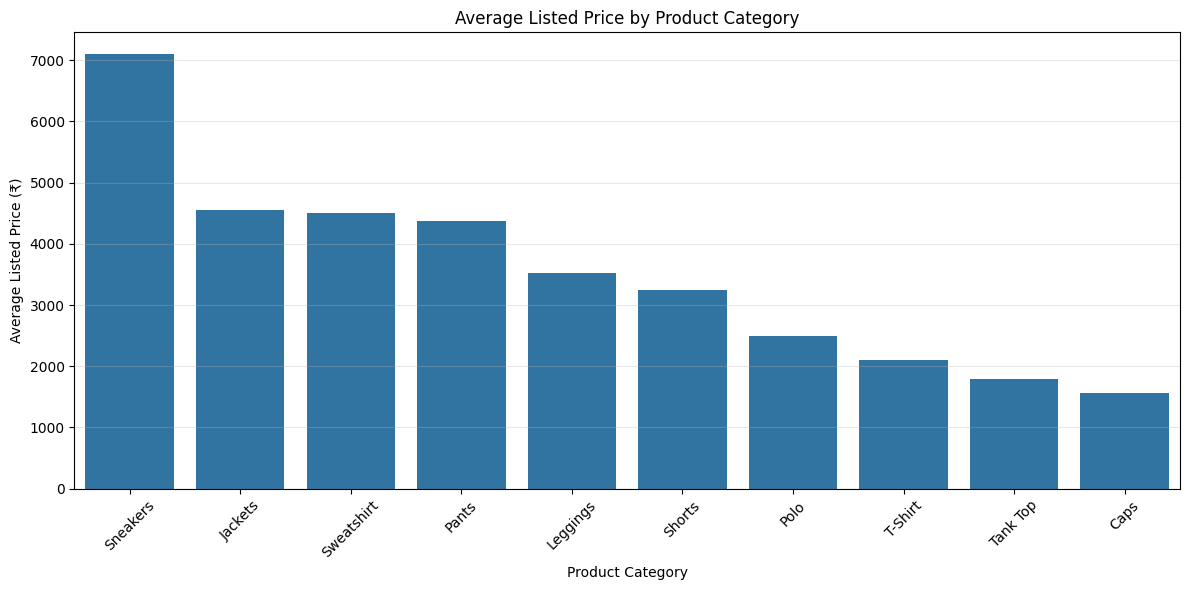

In [46]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=category_price_analysis,
    x="Category",
    y="Average_Price"
)

plt.title("Average Listed Price by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Listed Price (₹)")
plt.xticks(rotation=45)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
df["Category"] = df["Category"].replace({
    "Jacket": "Jackets",
    "Short": "Shorts"
})

In [4]:
df["Category"].value_counts()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Unique Categories:", df["Category"].nunique())

Rows: 250
Columns: 10
Unique Categories: 11


In [5]:
df.to_csv("one8_sports_final_cleaned.csv", index=False)

In [6]:
import os

print(os.path.exists("one8_sports_final_cleaned.csv"))

True


# Phase 6 – Advanced Python Business Analysis

In [7]:
# – Product Catalogue Quality Analysis

df["Catalogue_Score"] = df["Total Variants"] + df["Total Images"]

category_quality = (
    df.groupby("Category")
    .agg(
        Product_Listings=("Product Name", "count"),
        Avg_Variants=("Total Variants", "mean"),
        Avg_Images=("Total Images", "mean"),
        Avg_Catalogue_Score=("Catalogue_Score", "mean")
    )
    .round(2)
    .sort_values("Avg_Catalogue_Score", ascending=False)
)

display(category_quality)

,Product_Listings,Avg_Variants,Avg_Images,Avg_Catalogue_Score
Category,,,,
Sneakers,52,6.67,6.00,12.67
Short,3,6.00,6.00,12.00
Leggings,12,6.00,5.33,11.33
Sweatshirt,3,6.00,5.33,11.33
T-Shirt,61,5.95,5.31,11.26
Shorts,10,6.00,5.20,11.20
Polo,42,6.00,5.19,11.19
Pants,27,6.00,5.11,11.11
Jacket,11,6.00,5.00,11.00


# Business observations:

1. Sneakers lead with the highest average catalogue score (12.67).
2. Caps have the lowest score (8.08), mainly because they average only 1 variant.
3. T-Shirts have the highest number of listings (61).
4. Most categories have approximately 5–6 images per product.

In [8]:
# – Price vs Catalogue Characteristics

price_catalogue = df[
    ["Price", "Total Variants", "Total Images", "Catalogue_Score"]
].corr().round(2)

display(price_catalogue)

,Price,Total Variants,Total Images,Catalogue_Score
Price,1.00,0.43,-0.00,0.47
Total Variants,0.43,1.00,-0.44,0.79
Total Images,-0.00,-0.44,1.00,0.21
Catalogue_Score,0.47,0.79,0.21,1.00


# Business Insights
1. Products with more variants tend to have higher listed prices.
2. Number of images has almost no linear relationship with price.
3. Catalogue Score has a moderate positive correlation (0.47) with price.
4. Variants contribute more strongly to Catalogue Score than images.

In [9]:
# – Category-wise Portfolio Opportunity Analysis

df["Category_Avg_Price"] = df.groupby("Category")["Price"].transform("mean")

df["Category_Avg_Score"] = df.groupby("Category")["Catalogue_Score"].transform("mean")

opportunity_products = df[
    (df["Price"] < df["Category_Avg_Price"]) &
    (df["Catalogue_Score"] > df["Category_Avg_Score"])
]

print("Total Opportunity Products:", len(opportunity_products))

display(
    opportunity_products[
        ["Product Name", "Category", "Price", "Catalogue_Score"]
    ].sort_values("Catalogue_Score", ascending=False)
)

Total Opportunity Products: 38


,Product Name,Category,Price,Catalogue_Score
14,Seam Pavilion - Black,Sneakers,6999.0,17
15,Seam Pavilion - White,Sneakers,6999.0,17
16,Seam Pavilion - Off White,Sneakers,6999.0,16
62,Seam Classic - Legacy Red & White,Sneakers,4999.0,15
61,Seam Classic - Club Navy & White,Sneakers,4999.0,15
63,Seam Classic - Legacy Red & Black,Sneakers,4999.0,15
65,Seam Classic - Field Green & White,Sneakers,4999.0,15
64,Seam Classic - Jersey White & Black,Sneakers,4999.0,15
8,Seam XVIII X - Candy Pink,Sneakers,6999.0,14
13,Seam XVIII X - Green,Sneakers,6999.0,14


# Business Interpretation
1. These 38 products offer relatively stronger catalogue depth at below-category-average prices.
2. Sneakers feature prominently among the highest-scoring opportunities.
3. Caps also have several qualifying products, despite having the lowest average category catalogue score overall.
4. These products could be prioritised for further merchandising and promotional evaluation.

# Phase 7 :- Data Visualization

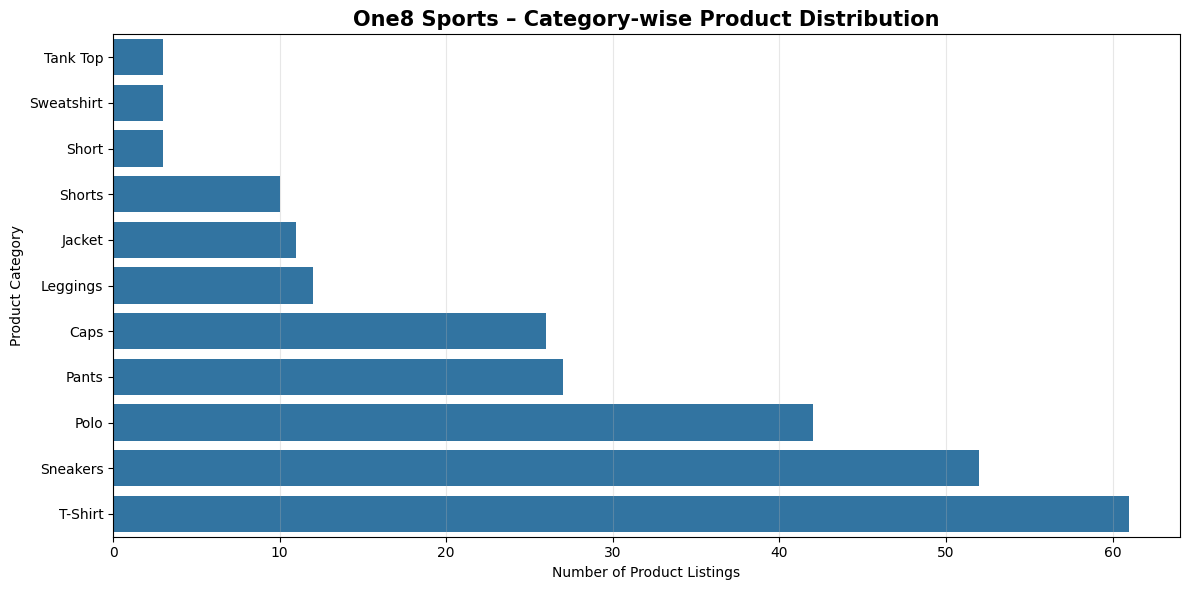

In [11]:
# – Category-wise Product Distribution

import matplotlib.pyplot as plt
import seaborn as sns

category_counts = df["Category"].value_counts().sort_values(ascending=True)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("One8 Sports – Category-wise Product Distribution",
          fontsize=15, fontweight="bold")

plt.xlabel("Number of Product Listings")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

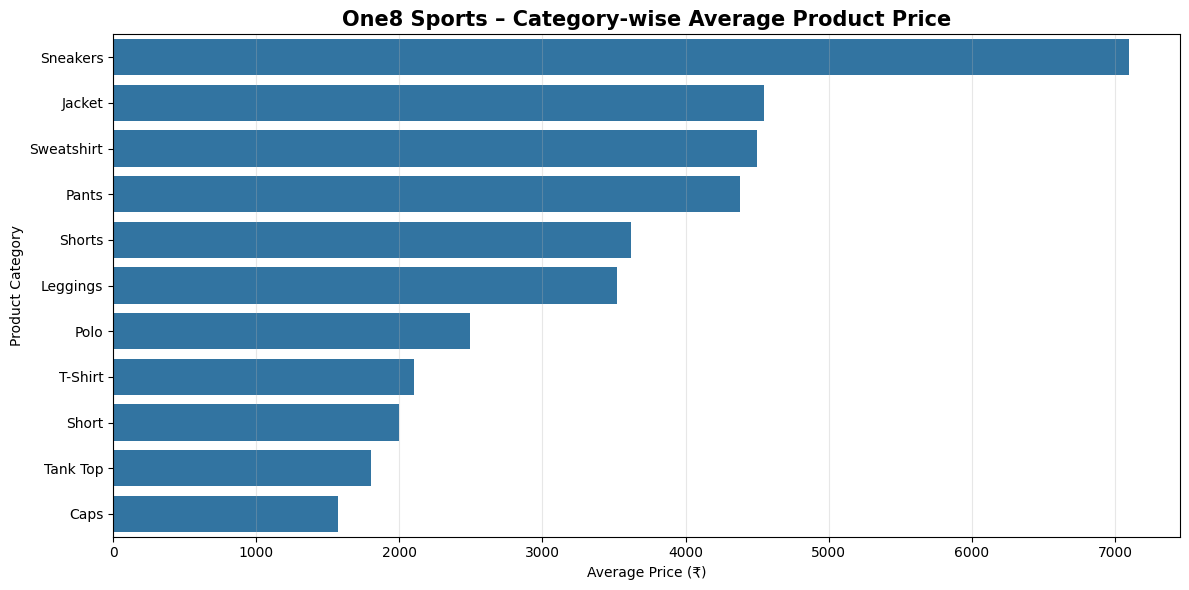

In [12]:
# – Category-wise Average Price

category_price = (
    df.groupby("Category")["Price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_price.values,
    y=category_price.index
)

plt.title("One8 Sports – Category-wise Average Product Price",
          fontsize=15, fontweight="bold")

plt.xlabel("Average Price (₹)")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

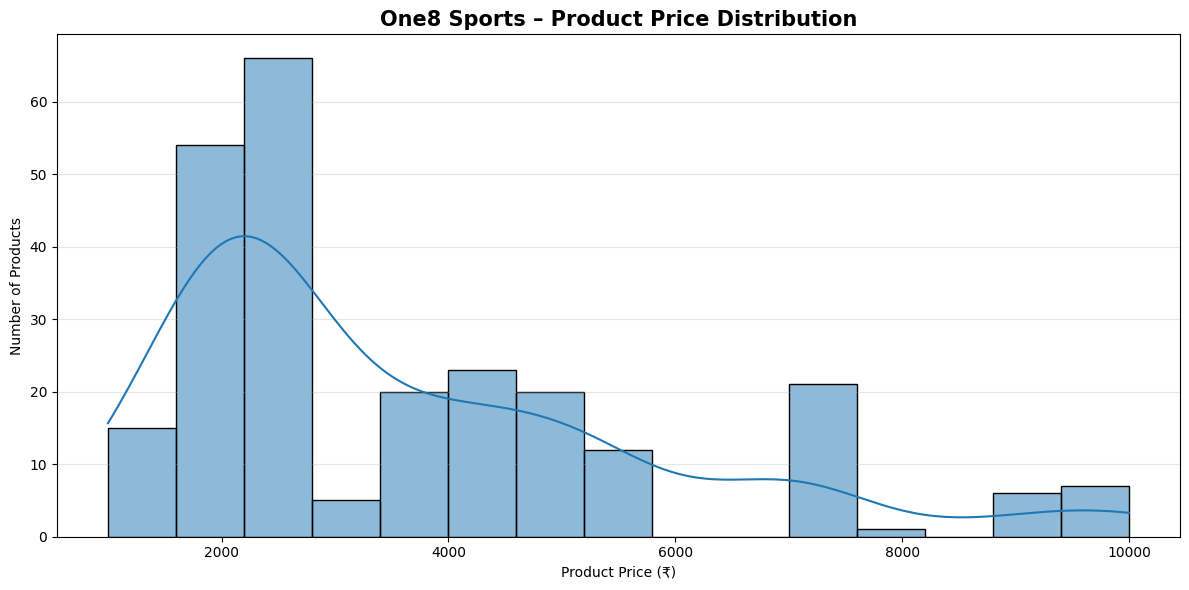

In [13]:
# – Overall Product Price Distribution

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Price",
    bins=15,
    kde=True
)

plt.title("One8 Sports – Product Price Distribution",
          fontsize=15, fontweight="bold")

plt.xlabel("Product Price (₹)")
plt.ylabel("Number of Products")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

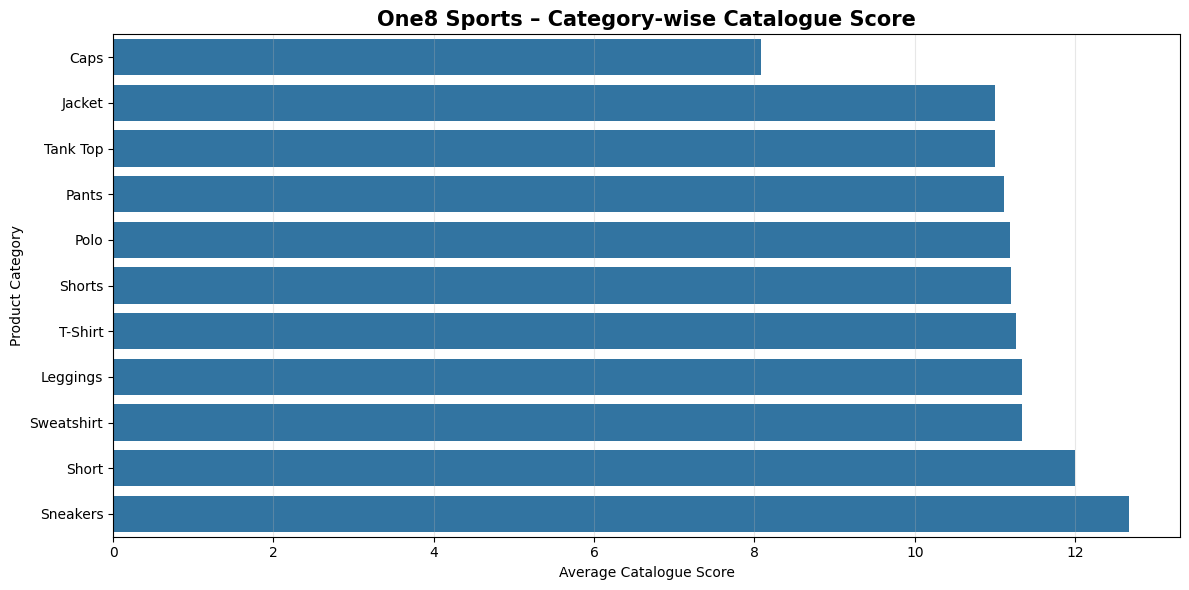

In [14]:
# – Category-wise Average Catalogue Score

category_score = (
    df.groupby("Category")["Catalogue_Score"]
    .mean()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_score.values,
    y=category_score.index
)

plt.title("One8 Sports – Category-wise Catalogue Score",
          fontsize=15, fontweight="bold")

plt.xlabel("Average Catalogue Score")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

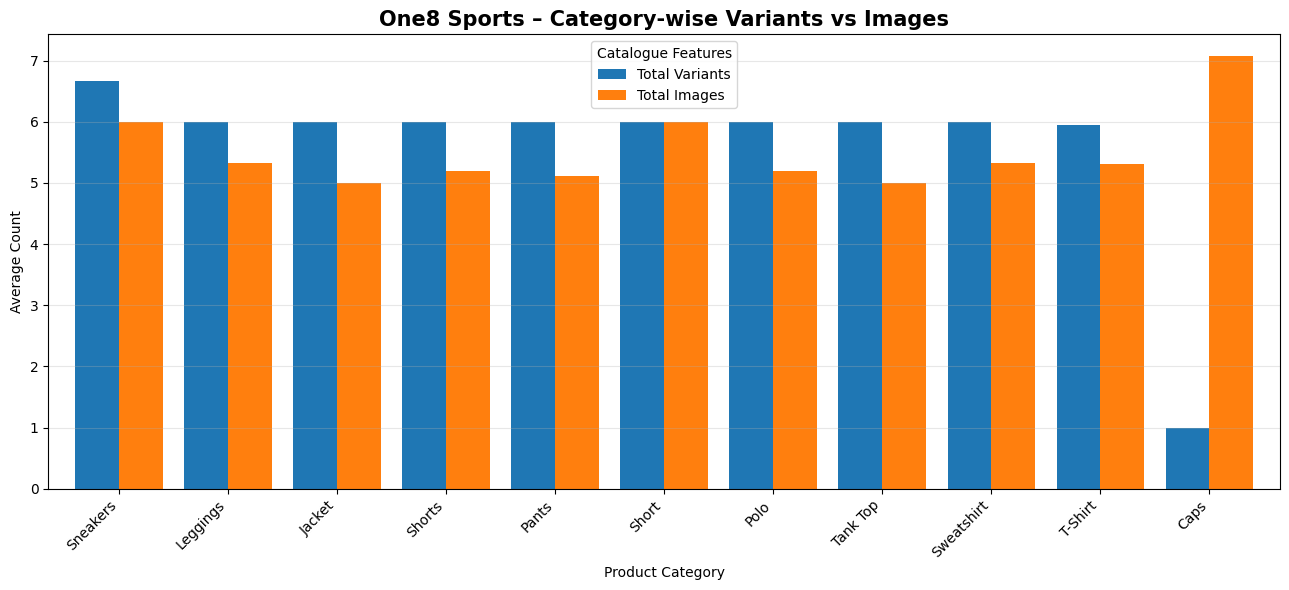

In [15]:
# – Variants vs Images by Category

category_features = (
    df.groupby("Category")[["Total Variants", "Total Images"]]
    .mean()
    .sort_values("Total Variants", ascending=False)
)

category_features.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("One8 Sports – Category-wise Variants vs Images",
          fontsize=15, fontweight="bold")

plt.xlabel("Product Category")
plt.ylabel("Average Count")

plt.xticks(rotation=45, ha="right")
plt.legend(title="Catalogue Features")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

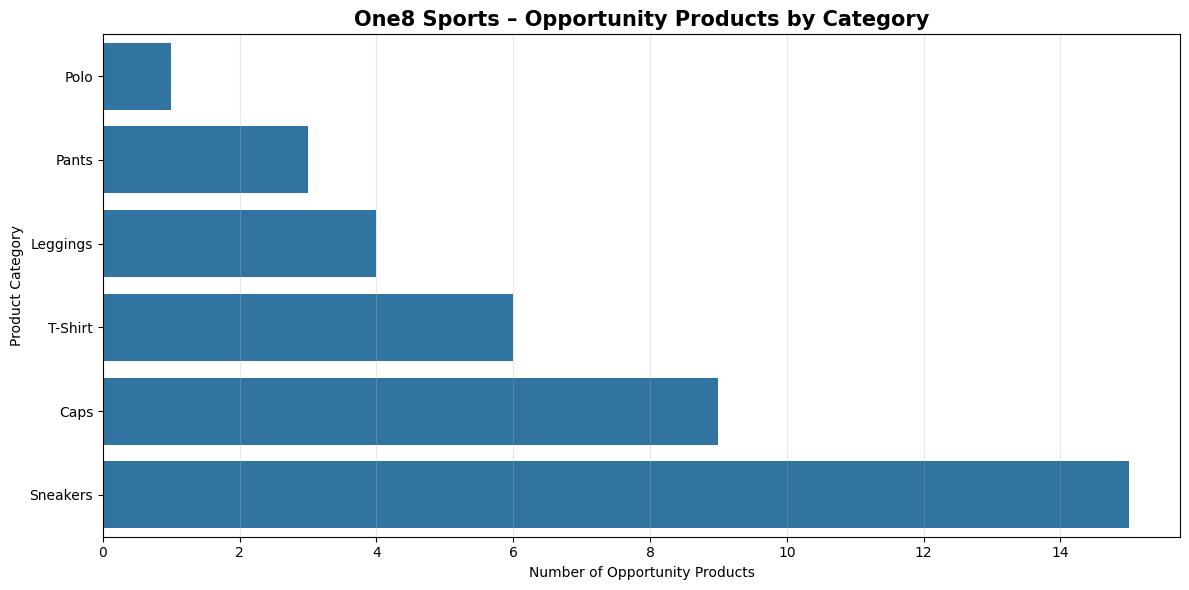

In [16]:
# – Opportunity Products by Category

opportunity_category = (
    opportunity_products["Category"]
    .value_counts()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=opportunity_category.values,
    y=opportunity_category.index
)

plt.title("One8 Sports – Opportunity Products by Category",
          fontsize=15, fontweight="bold")

plt.xlabel("Number of Opportunity Products")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

#  Phase 8 – Business Insights & Recommendations

## 1. Executive Business Summary

This project analyses 250 product listings from One8 Sports to evaluate its product portfolio, pricing structure, catalogue characteristics and potential product-level opportunities.

### Key Findings

1. **Product Portfolio:** T-Shirts represent the largest category with 61 listings, followed by Sneakers (52) and Polo (42).

2. **Pricing Structure:** The average listed product price is approximately ₹3,659, while the median price is ₹2,599, indicating a concentration of products in relatively affordable price ranges.

3. **Catalogue Quality:** Sneakers have the highest average catalogue score (12.67), while Caps have the lowest (8.08). The score combines product variants and images as a basic catalogue-completeness proxy.

4. **Pricing and Catalogue Relationship:** Product price shows a moderate positive correlation (0.47) with catalogue score. Since catalogue score is calculated using product variants and images, its relationship with these individual components should be interpreted carefully.


5. **Product Opportunities:** The analysis identified 38 products priced below their respective category averages while maintaining above-average catalogue scores.

### Overall Conclusion

The analysis highlights differences in product assortment, pricing and catalogue presentation across One8 Sports categories. These findings can help identify categories requiring catalogue improvements and products that may deserve further commercial evaluation.

**Data Limitation:** This project analyses scraped product catalogue data, not actual sales transactions. Therefore, conclusions about revenue, profitability, customer demand and sales performance cannot be established from this dataset.


# Business Recommendations

### 1. Improve Catalogue Presentation

Caps have the lowest average catalogue score (8.08). One8 Sports could review their product images and available variants to identify opportunities for improving catalogue completeness.

### 2. Review Premium Pricing

Sneakers have the highest average listed price (approximately ₹7,099). The business could review premium product positioning and ensure that product information and presentation adequately communicate product features.

### 3. Evaluate Product-Level Opportunities

The analysis identified 38 products priced below their respective category averages while maintaining above-average catalogue scores. These products could be prioritised for further commercial evaluation.

### 4. Review Product Portfolio Distribution

T-Shirts have the highest number of listings (61), while several categories have considerably fewer listings. One8 Sports could review category-wise assortment distribution to identify potential portfolio gaps.

### Recommendation Limitation

These recommendations are based on scraped product catalogue data. Actual sales, customer demand, conversion rates and profitability data would be required before making final business decisions.
